# FireLens - Exploratory analysis of MODIS and VIIRS hotspots

**Data:** NASA FIRMS Area API, Standard Processing (science-quality) products
`MODIS_SP` (Collection 6.1, Terra + Aqua, ~1 km) and `VIIRS_SNPP_SP` (Suomi NPP, 375 m),
retrieved by the FireLens pipeline and validated into Parquet.

**Study window:** California bounding box (-124.5, 32.5, -114.0, 42.1), 2018-01-01 to 2021-12-31,
plus a one-day global snapshot (2020-09-01) to verify global retrieval.

> **Important:** every record is a *hotspot detection* - a satellite pixel containing one or more
> thermal anomalies at overpass time. A single wildfire produces many detections per overpass and is
> observed on many overpasses. Detection counts are **not** counts of fires, and MODIS and VIIRS counts
> are **not** directly comparable because the sensors have different pixel sizes and sensitivities.
>
> The California *bounding box* also contains parts of Oregon, Nevada, Arizona, Baja California and ocean.

In [1]:
import json
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

from firelens.config import load_settings
from firelens.catalog import REGIONS
from firelens.cleaning import load_detections
from firelens.pipeline import availability_table, grid_dir, read_grid_table
from firelens.coverage import fetch_missing_dates
from firelens.harmonization import regional_monthly
from firelens import plots
from firelens.plots import SENSOR_COLORS, PLATFORM_COLORS, SENSOR_CMAPS

plots.apply_style()
pd.set_option("display.width", 140)
S = load_settings(require_key=False)
REGION = REGIONS["california"]
START, END = date(2018, 1, 1), date(2021, 12, 31)
FIG = S.figures_dir
TAG = f"{START}_{END}_0.25deg"
summary = {}  # collected statistics, written to reports/results/eda_summary.json

## 1. Data inventory and quality control

In [2]:
avail = availability_table(S)
display(avail[avail.data_id.isin(["MODIS_SP", "VIIRS_SNPP_SP"])])

modis = load_detections(S, REGION, "MODIS_SP", START, END)
viirs = load_detections(S, REGION, "VIIRS_SNPP_SP", START, END)
det = {"MODIS": modis, "VIIRS": viirs}

rows = []
for name, d in det.items():
    qc = [c for c in d.columns if c.startswith("qc_") and c != "qc_usable"]
    rows.append({"sensor": name, "records": len(d), "usable": int(d.qc_usable.sum()),
                 "first": d.acq_date.min().date(), "last": d.acq_date.max().date(),
                 "platforms": ", ".join(sorted(d.platform.dropna().unique())),
                 "product versions": ", ".join(sorted(d.version.unique())),
                 **{f: int(d[f].sum()) for f in qc}})
inventory = pd.DataFrame(rows).set_index("sensor").T
display(inventory)
summary["inventory"] = inventory.astype(str).to_dict()

,data_id,min_date,max_date
1,MODIS_SP,2000-11-01,2026-08-31
7,VIIRS_SNPP_SP,2012-01-20,2026-07-31


sensor,MODIS,VIIRS
records,130239,585222
usable,130239,585222
first,2018-01-01,2018-01-01
last,2021-12-29,2021-12-31
platforms,"Aqua, Terra",Suomi NPP
product versions,6.03,2
qc_parse_error,0,0
qc_time_invalid,0,0
qc_confidence_invalid,0,0
qc_coord_invalid,0,0


All QC checks are recorded as flags; no rows are deleted. `qc_non_vegetation_type` marks FIRMS
`type` 1-3 (volcano, other static land source such as industrial heat, offshore). These are kept in the
detection tables and counted separately (`n_vegetation`) during aggregation.

## 2. MODIS detection counts over time

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


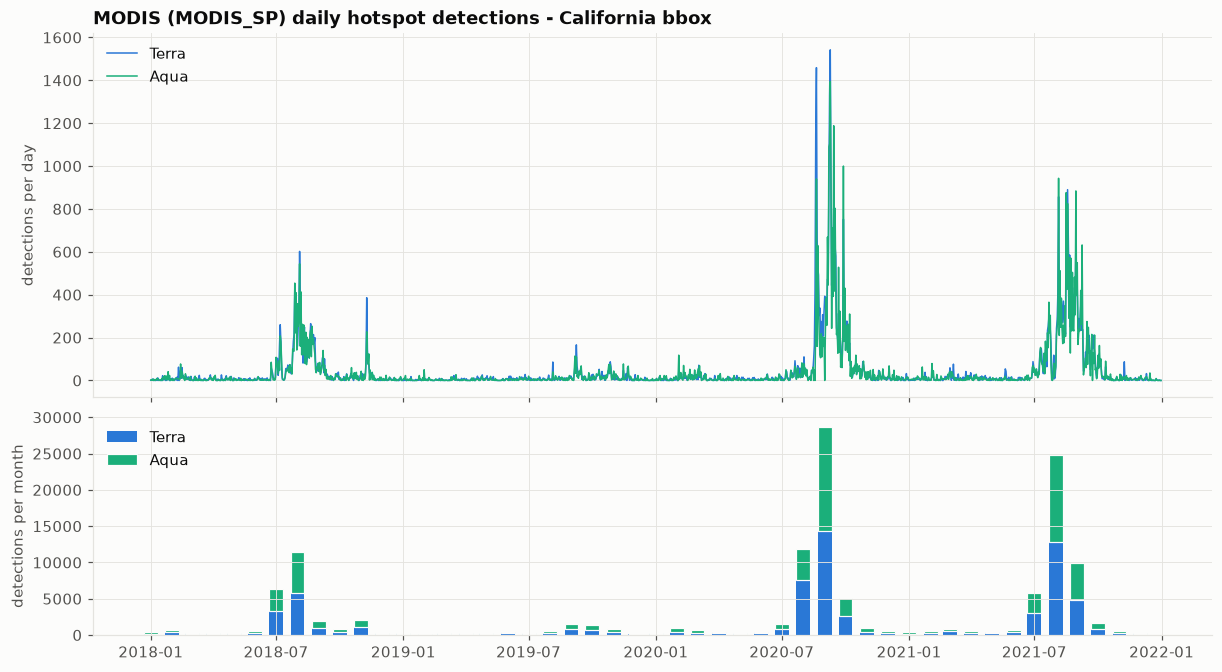

In [3]:
def daily_counts(d, by=None):
    u = d[d.qc_usable]
    keys = ["acq_date"] + ([by] if by else [])
    out = u.groupby(keys).size()
    if by:
        out = out.unstack(by)
    full = pd.date_range(START, END, freq="D")
    return out.reindex(full).fillna(0)

m_daily = daily_counts(modis, "platform")
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1.2]})
for p in ["Terra", "Aqua"]:
    axes[0].plot(m_daily.index, m_daily[p], lw=1.0, color=PLATFORM_COLORS[p], label=p)
axes[0].set_ylabel("detections per day")
axes[0].set_title("MODIS (MODIS_SP) daily hotspot detections - California bbox")
axes[0].legend(loc="upper left")
m_month = modis[modis.qc_usable].groupby([modis.acq_date.dt.to_period("M"), "platform"]).size().unstack().fillna(0)
x = m_month.index.to_timestamp()
axes[1].bar(x, m_month["Terra"], width=20, color=PLATFORM_COLORS["Terra"], label="Terra")
axes[1].bar(x, m_month["Aqua"], width=20, bottom=m_month["Terra"], color=PLATFORM_COLORS["Aqua"], label="Aqua",
            edgecolor=plots.SURFACE, linewidth=0.8)
axes[1].set_ylabel("detections per month")
axes[1].legend(loc="upper left")
plots.save(fig, FIG, "01_modis_counts_over_time"); plt.show()
summary["modis_terra_share"] = float(m_daily["Terra"].sum() / m_daily.sum().sum())

## 3. VIIRS detection counts over time

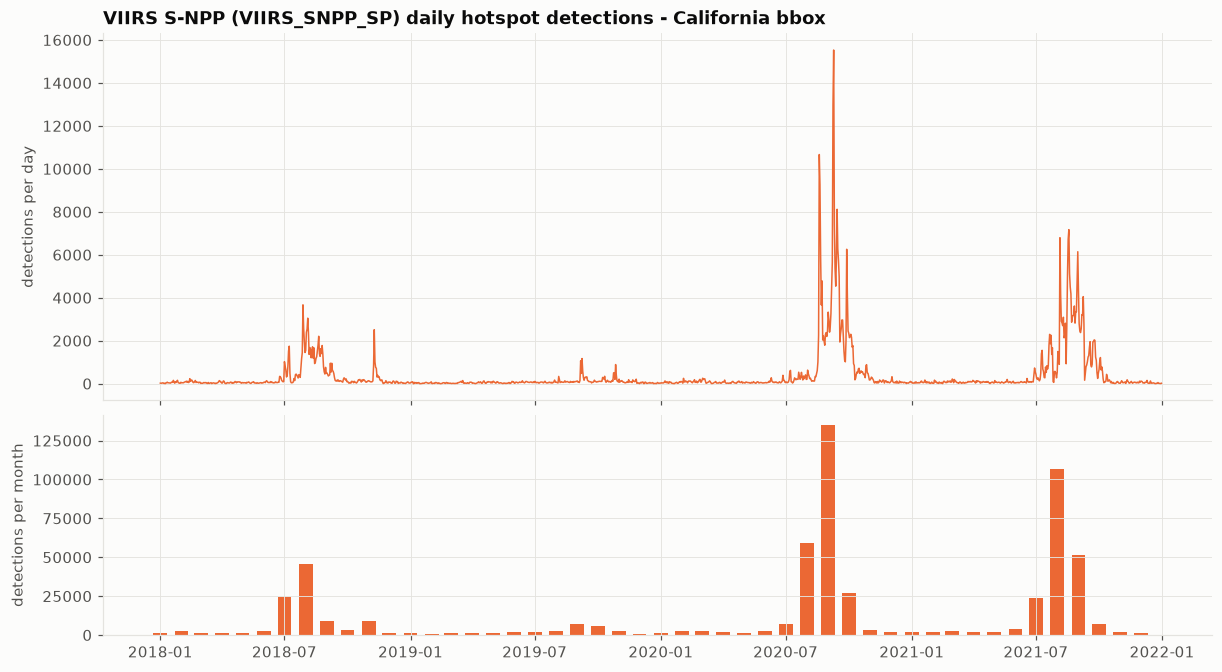

Peak detection day: {'MODIS': datetime.date(2020, 9, 9), 'VIIRS': datetime.date(2020, 9, 9)}


In [4]:
v_daily = daily_counts(viirs)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1.2]})
axes[0].plot(v_daily.index, v_daily.values, lw=1.0, color=SENSOR_COLORS["VIIRS"])
axes[0].set_ylabel("detections per day")
axes[0].set_title("VIIRS S-NPP (VIIRS_SNPP_SP) daily hotspot detections - California bbox")
v_month = viirs[viirs.qc_usable].groupby(viirs.acq_date.dt.to_period("M")).size()
axes[1].bar(v_month.index.to_timestamp(), v_month.values, width=20, color=SENSOR_COLORS["VIIRS"])
axes[1].set_ylabel("detections per month")
plots.save(fig, FIG, "02_viirs_counts_over_time"); plt.show()

peaks = pd.DataFrame({"MODIS": m_daily.sum(axis=1), "VIIRS": v_daily}).idxmax().dt.date
print("Peak detection day:", peaks.to_dict())
summary["peak_day"] = {k: str(v) for k, v in peaks.items()}

## 4. Geographic distribution of hotspots

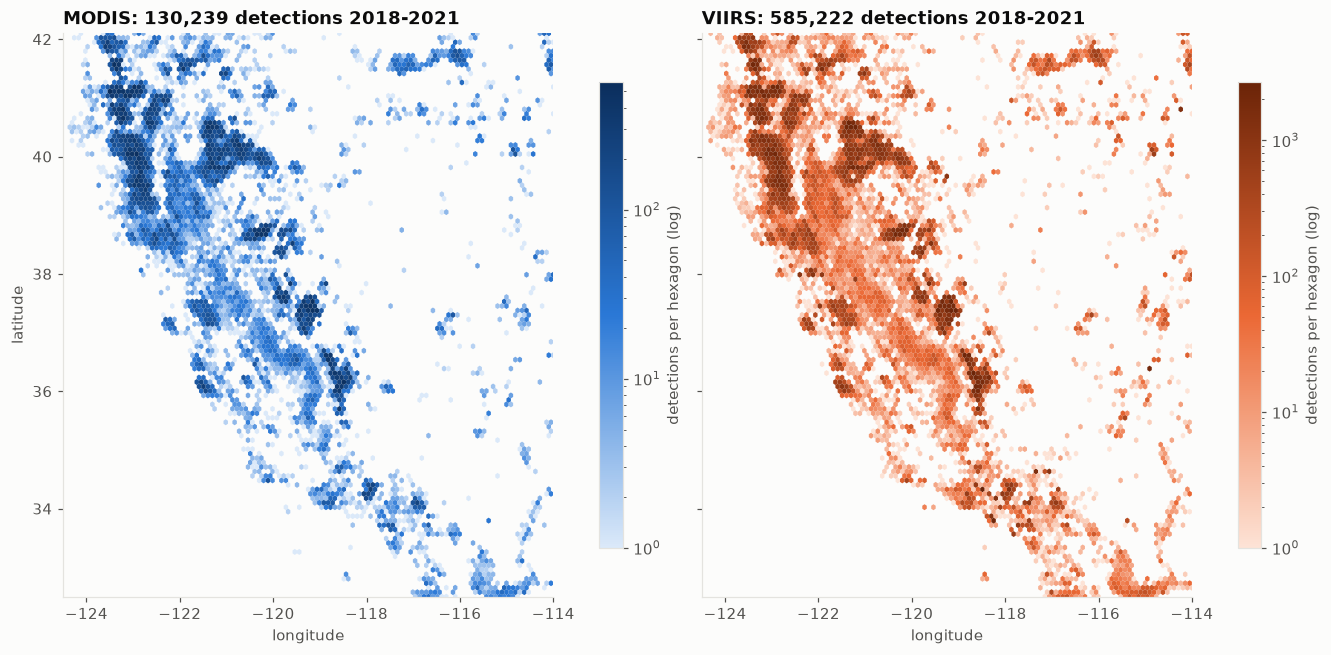

In [5]:
ext = REGION.bbox
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2), sharey=True)
for ax, (name, d) in zip(axes, det.items()):
    u = d[d.qc_usable]
    hb = ax.hexbin(u.longitude, u.latitude, gridsize=110, extent=(ext.west, ext.east, ext.south, ext.north),
                   bins="log", cmap=SENSOR_CMAPS[name], mincnt=1, linewidths=0)
    ax.set_xlim(ext.west, ext.east); ax.set_ylim(ext.south, ext.north)
    plots.lonlat_aspect(ax, 37.3)
    ax.set_title(f"{name}: {len(u):,} detections 2018-2021")
    ax.set_xlabel("longitude"); ax.grid(False)
    fig.colorbar(hb, ax=ax, shrink=0.7, label="detections per hexagon (log)")
axes[0].set_ylabel("latitude")
plots.save(fig, FIG, "03_hotspot_maps"); plt.show()

In [6]:
grid = read_grid_table(grid_dir(S, REGION) / f"grid_monthly_{TAG}.parquet")
cells = grid.groupby(["sensor", "cell_id"]).agg(n=("n_detections", "sum")).reset_index()
active = cells.groupby("sensor").agg(active_cells=("cell_id", "nunique"), detections=("n", "sum"))
active["detections_per_active_cell"] = active.detections / active.active_cells
both_cells = set(cells[cells.sensor == "MODIS"].cell_id) & set(cells[cells.sensor == "VIIRS"].cell_id)
display(active)
print(f"0.25 deg cells with detections from both sensors: {len(both_cells)}; "
      f"MODIS-only: {len(set(cells[cells.sensor=='MODIS'].cell_id) - both_cells)}; "
      f"VIIRS-only: {len(set(cells[cells.sensor=='VIIRS'].cell_id) - both_cells)}")
summary["active_cells"] = active.round(2).to_dict()
summary["cells_both"] = len(both_cells)

,active_cells,detections,detections_per_active_cell
sensor,,,
MODIS,784,130239,166.121173
VIIRS,896,585222,653.149554


0.25 deg cells with detections from both sensors: 754; MODIS-only: 30; VIIRS-only: 142


## 5. Monthly and annual fire activity

MODIS                                                              VIIRS                                                        
     detections vegetation (type 0) FRP total (GW) days with detections detections vegetation (type 0) FRP total (GW) days with detections
year                                                                                                                                      
2018      25417               24999         3222.9                  349     103464               95635         1814.8                  364
2019       6439                6127          541.3                  319      28845               21902          351.7                  361
2020      51866               51507         7346.8                  352     246837              239054         4540.8                  365
2021      46517               46191         6894.7                  351     206076              198766         4076.8                  364

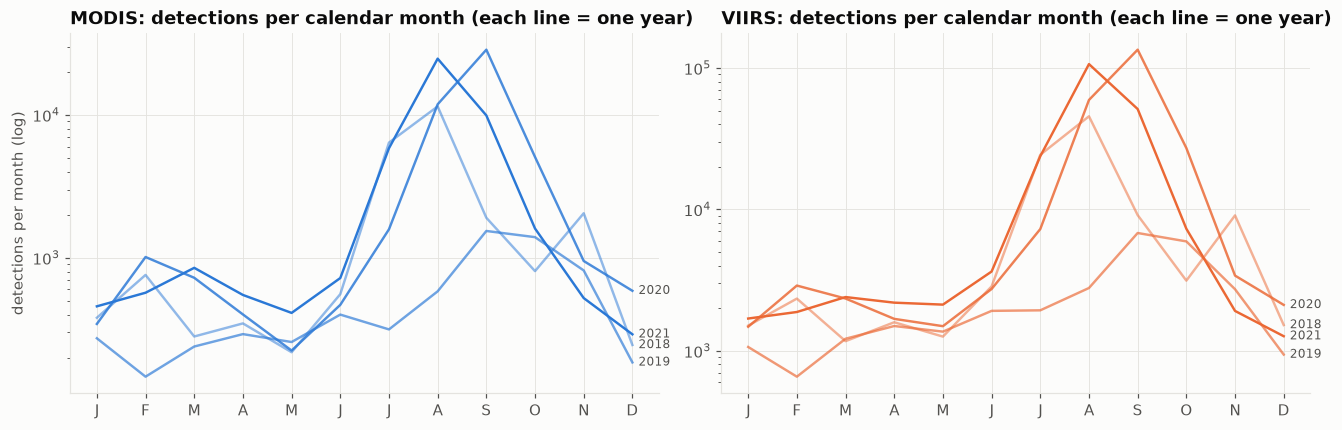

In [7]:
def annual_stats(d):
    u = d[d.qc_usable]
    g = u.groupby(u.acq_date.dt.year)
    return pd.DataFrame({"detections": g.size(), "vegetation (type 0)": g.fire_type.apply(lambda s: int((s == 0).sum())),
                         "FRP total (GW)": g.frp_mw.sum() / 1e3, "days with detections": g.acq_date.nunique()})
annual = pd.concat({name: annual_stats(d) for name, d in det.items()}, axis=1)
annual.index.name = "year"
display(annual.round(1))
summary["annual"] = {f"{a}|{b}": {int(k): float(v) for k, v in annual[(a, b)].items()} for a, b in annual.columns}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for ax, name in zip(axes, det):
    d = det[name][det[name].qc_usable]
    mm = d.groupby([d.acq_date.dt.year, d.acq_date.dt.month]).size().unstack(0).reindex(range(1, 13)).fillna(0)
    for i, y in enumerate(mm.columns):
        ax.plot(mm.index, mm[y], lw=1.6, alpha=0.35 + 0.65 * (i + 1) / len(mm.columns),
                color=SENSOR_COLORS[name], label=str(y))
        ax.annotate(str(y), (mm.index[-1], mm[y].iloc[-1]), xytext=(4, 0), textcoords="offset points",
                    fontsize=8, color=plots.TEXT_2, va="center")
    ax.set_yscale("log"); ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
    ax.set_title(f"{name}: detections per calendar month (each line = one year)")
axes[0].set_ylabel("detections per month (log)")
plots.save(fig, FIG, "04_seasonal_cycle"); plt.show()

Fire activity in this region is strongly seasonal (summer-autumn peak) and dominated by a few extreme
months. Inter-annual variability is very large, so four years are far too short for trend statements.

## 6. Differences between MODIS and VIIRS

MODIS_SP combines **Terra** (~10:30 / 22:30 local overpass) and **Aqua** (~13:30 / 01:30), while VIIRS
S-NPP overpasses at ~13:30 / 01:30. Comparing VIIRS with Terra+Aqua therefore mixes sensor differences with
a difference in the number and timing of overpasses. Aqua-only is the like-for-like reference.

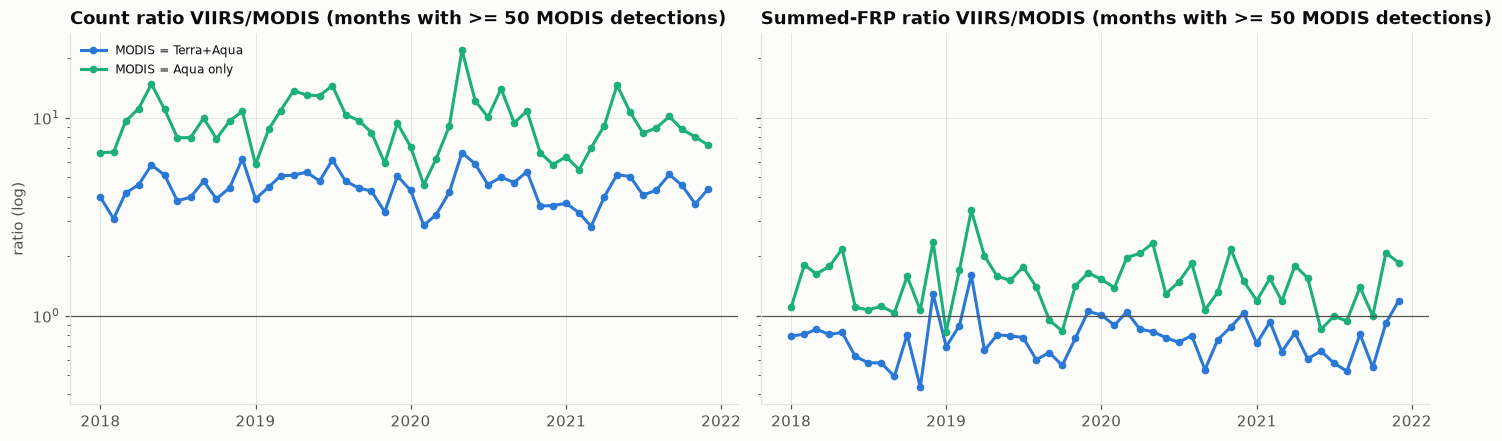

,count VIIRS/Terra+Aqua,count VIIRS/Aqua,FRP VIIRS/Terra+Aqua,FRP VIIRS/Aqua
count,48.00,48.00,48.00,48.00
mean,4.47,9.59,0.79,1.52
std,0.87,3.18,0.21,0.50
min,2.82,4.59,0.44,0.83
25%,3.90,7.25,0.64,1.10
50%,4.42,9.26,0.79,1.50
75%,5.08,10.83,0.86,1.80
max,6.67,21.96,1.60,3.41


In [8]:
cov = read_grid_table(grid_dir(S, REGION) / f"coverage_monthly_{START}_{END}.parquet")
def monthly(d, platforms=None):
    u = d[d.qc_usable & (d.platform.isin(platforms) if platforms else True)]
    g = u.groupby(u.acq_date.dt.to_period("M"))
    return pd.DataFrame({"n": g.size(), "frp": g.frp_mw.sum()})
mv, mta, maq = monthly(viirs), monthly(modis), monthly(modis, ["Aqua"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), sharey=True)
for ax, col, title in [(axes[0], "n", "Count ratio VIIRS/MODIS"), (axes[1], "frp", "Summed-FRP ratio VIIRS/MODIS")]:
    for ref, lab, c in [(mta, "MODIS = Terra+Aqua", SENSOR_COLORS["MODIS"]), (maq, "MODIS = Aqua only", plots.SERIES[2])]:
        ok = ref.n >= 50   # ratios of tiny numbers are noise
        r = (mv[col] / ref[col])[ok]
        ax.plot(r.index.to_timestamp(), r.values, marker="o", ms=4, color=c, label=lab)
    ax.axhline(1, color=plots.TEXT_2, lw=0.8)
    ax.set_yscale("log"); ax.set_title(f"{title} (months with >= 50 MODIS detections)")
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].set_ylabel("ratio (log)"); axes[0].legend(loc="upper left", fontsize=8)
plots.save(fig, FIG, "05_monthly_ratio"); plt.show()
ratio_tbl = pd.DataFrame({
    "count VIIRS/Terra+Aqua": (mv.n / mta.n)[mta.n >= 50], "count VIIRS/Aqua": (mv.n / maq.n)[maq.n >= 50],
    "FRP VIIRS/Terra+Aqua": (mv.frp / mta.frp)[mta.n >= 50], "FRP VIIRS/Aqua": (mv.frp / maq.frp)[maq.n >= 50]})
desc = ratio_tbl.describe().round(2)
display(desc)
summary["monthly_ratio"] = desc.to_dict()
summary["aqua_share_of_modis"] = float(maq.n.sum() / mta.n.sum())

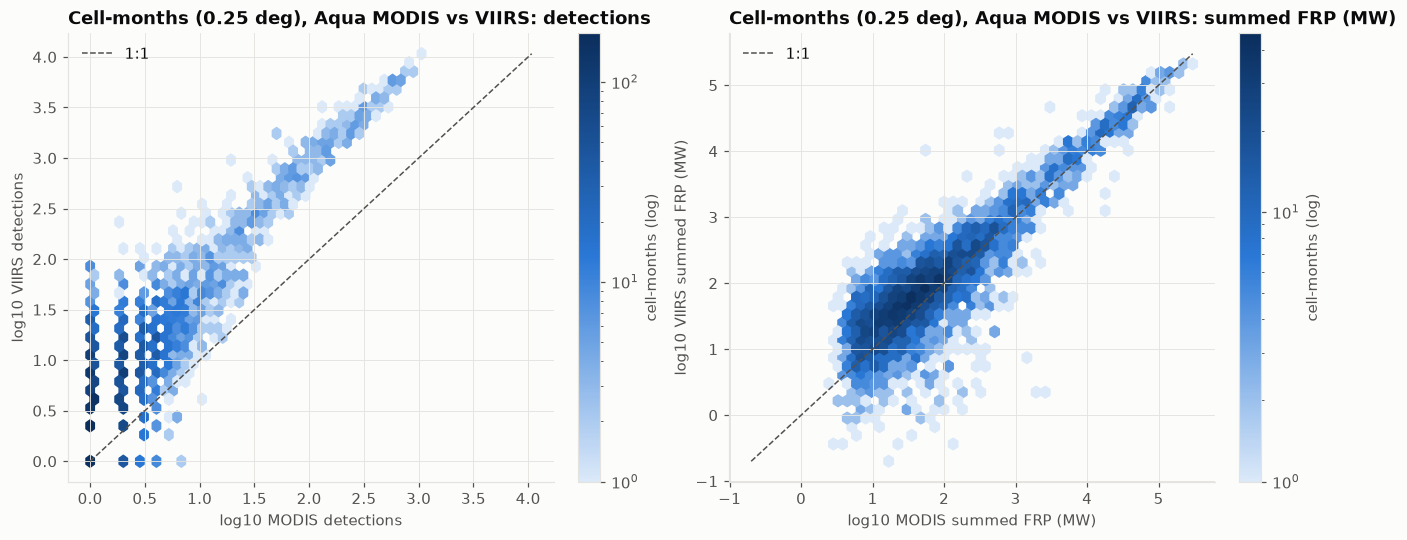

Share of active cell-months, Aqua MODIS vs VIIRS (both observed):
both detected    0.331
VIIRS only       0.641
MODIS only       0.028


In [9]:
hf = read_grid_table(grid_dir(S, REGION) / f"harmonization_prep_aqua_{TAG}.parquet")  # Aqua-only MODIS
h = hf[hf.both_observed & ((hf.modis_n_detections > 0) | (hf.viirs_n_detections > 0))]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, metric, lab in [(axes[0], "n_detections", "detections"), (axes[1], "frp_sum_mw", "summed FRP (MW)")]:
    mx, vy = h[f"modis_{metric}"], h[f"viirs_{metric}"]
    b = (mx > 0) & (vy > 0)
    hb = ax.hexbin(np.log10(mx[b]), np.log10(vy[b]), gridsize=40, bins="log", cmap=plots.SEQ_BLUE, mincnt=1)
    lim = [min(np.log10(mx[b]).min(), np.log10(vy[b]).min()), max(np.log10(mx[b]).max(), np.log10(vy[b]).max())]
    ax.plot(lim, lim, color=plots.TEXT_2, lw=1, ls="--", label="1:1")
    ax.set_xlabel(f"log10 MODIS {lab}"); ax.set_ylabel(f"log10 VIIRS {lab}")
    ax.set_title(f"Cell-months (0.25 deg), Aqua MODIS vs VIIRS: {lab}")
    ax.legend(loc="upper left")
    fig.colorbar(hb, ax=ax, label="cell-months (log)")
plots.save(fig, FIG, "06_cellmonth_scatter"); plt.show()
share = pd.Series({
    "both detected": ((h.modis_n_detections > 0) & (h.viirs_n_detections > 0)).mean(),
    "VIIRS only": ((h.modis_n_detections == 0) & (h.viirs_n_detections > 0)).mean(),
    "MODIS only": ((h.modis_n_detections > 0) & (h.viirs_n_detections == 0)).mean()})
print("Share of active cell-months, Aqua MODIS vs VIIRS (both observed):"); print(share.round(3).to_string())
summary["cellmonth_share"] = share.round(4).to_dict()

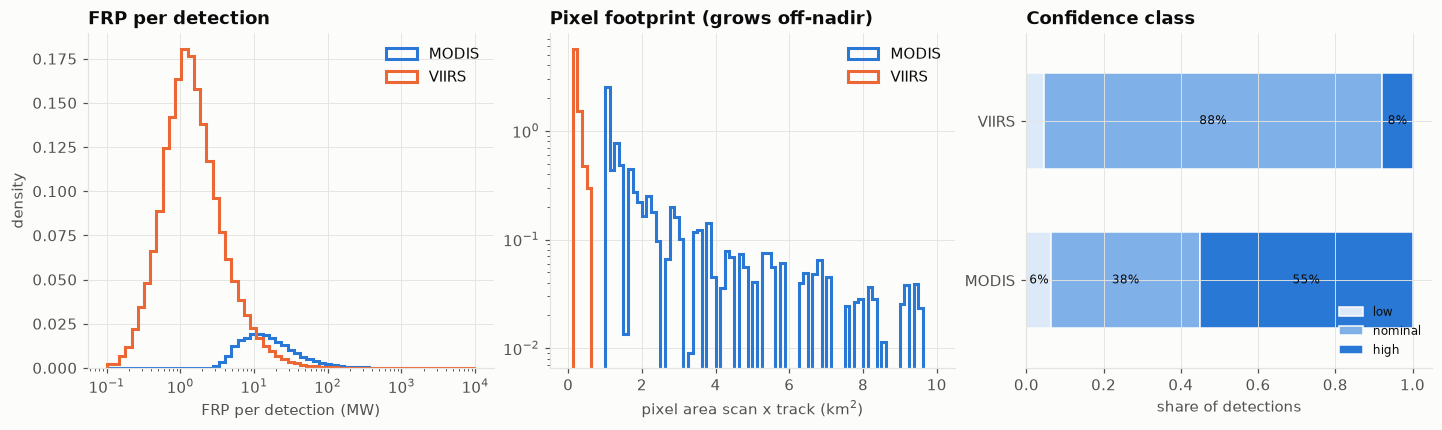

,MODIS,VIIRS
FRP median (MW),40.600,4.770
FRP mean (MW),138.252,18.427
FRP p95 (MW),548.710,79.560
FRP == 0 (count),146.000,1273.000
pixel area median (km2),1.430,0.202
pixel area max (km2),9.600,0.624
night share,0.461,0.634
brightness max (K),508.800,367.000
brightness < 300 K (count),0.000,46325.000


                  MODIS  VIIRS
confidence_class              
low               0.064  0.045
nominal           0.384  0.876
high              0.552  0.079


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
bins = np.logspace(-1, 4, 60)
for name, d in det.items():
    u = d[d.qc_usable & (d.frp_mw > 0)]
    axes[0].hist(u.frp_mw, bins=bins, density=True, histtype="step", lw=2, color=SENSOR_COLORS[name], label=name)
axes[0].set_xscale("log"); axes[0].set_xlabel("FRP per detection (MW)"); axes[0].set_ylabel("density")
axes[0].set_title("FRP per detection"); axes[0].legend()

for name, d in det.items():
    u = d[d.qc_usable]
    axes[1].hist(u.pixel_area_km2, bins=np.linspace(0, 10, 81), density=True, histtype="step", lw=2,
                 color=SENSOR_COLORS[name], label=name)
axes[1].set_yscale("log"); axes[1].set_xlabel("pixel area scan x track (km$^2$)")
axes[1].set_title("Pixel footprint (grows off-nadir)"); axes[1].legend()

conf = pd.DataFrame({n: d[d.qc_usable].confidence_class.value_counts(normalize=True) for n, d in det.items()}).reindex(["low", "nominal", "high"])
conf.T.plot.barh(stacked=True, ax=axes[2], color=["#dbe9f9", "#7fb0e8", "#2a78d6"], edgecolor=plots.SURFACE, width=0.6)
axes[2].set_xlabel("share of detections"); axes[2].set_title("Confidence class"); axes[2].legend(loc="lower right", fontsize=8)
for c in axes[2].containers:
    axes[2].bar_label(c, labels=[f"{w:.0%}" if w > 0.06 else "" for w in c.datavalues], label_type="center", fontsize=8)
plots.save(fig, FIG, "07_frp_pixel_confidence"); plt.show()

stats_tbl = pd.DataFrame({n: {
    "FRP median (MW)": d[d.qc_usable].frp_mw.median(),
    "FRP mean (MW)": d[d.qc_usable].frp_mw.mean(),
    "FRP p95 (MW)": d[d.qc_usable].frp_mw.quantile(0.95),
    "FRP == 0 (count)": int((d[d.qc_usable].frp_mw == 0).sum()),
    "pixel area median (km2)": d[d.qc_usable].pixel_area_km2.median(),
    "pixel area max (km2)": d[d.qc_usable].pixel_area_km2.max(),
    "night share": (d[d.qc_usable].daynight == "N").mean(),
    "brightness max (K)": d[d.qc_usable].brightness_k.max(),
    "brightness < 300 K (count)": int((d[d.qc_usable].brightness_k < 300).sum()),
} for n, d in det.items()}).round(3)
display(stats_tbl)
summary["sensor_stats"] = stats_tbl.to_dict()
print(conf.round(3))
summary["confidence_shares"] = conf.round(4).to_dict()

## 7. Temporal coverage and missing observations

,days_retrieved,platform_days_operational,platform_days_observed,platform_days_firms_missing
source,,,,
MODIS_SP,1461,2922,2922,0
VIIRS_SNPP_SP,1461,1461,1461,0


FIRMS-listed days with missing data in the study window:


,count,min,max
platform,,,


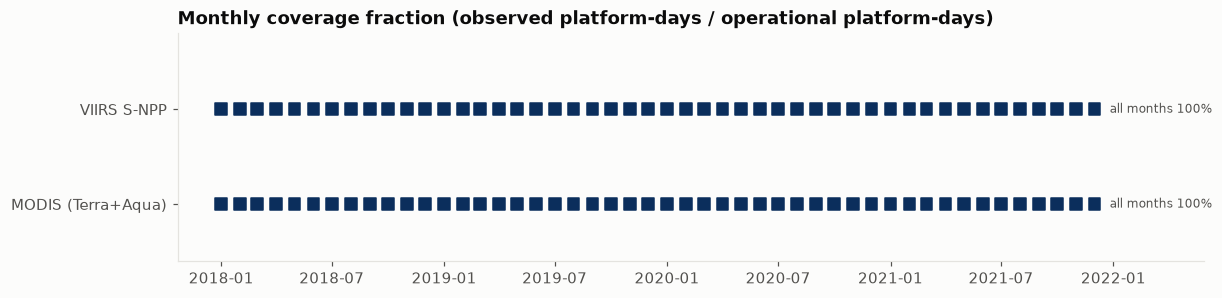

Days in window with zero detections in the bbox (not necessarily missing data): {'MODIS': 90, 'VIIRS': 7}


In [11]:
cov_t = cov.pivot(index="month", columns="source", values="coverage_fraction")
display(cov.groupby("source")[["days_retrieved", "platform_days_operational", "platform_days_observed",
                              "platform_days_firms_missing"]].sum())
missing = fetch_missing_dates(S)
if missing is not None:
    mwin = missing[(pd.to_datetime(missing.date) >= pd.Timestamp(START)) & (pd.to_datetime(missing.date) <= pd.Timestamp(END))]
    print("FIRMS-listed days with missing data in the study window:")
    display(mwin.groupby("platform").date.agg(["count", "min", "max"]))
    summary["firms_missing_in_window"] = mwin.groupby("platform").date.count().to_dict()

fig, ax = plt.subplots(figsize=(11, 2.6))
for i, (src, name) in enumerate([("MODIS_SP", "MODIS"), ("VIIRS_SNPP_SP", "VIIRS")]):
    v = cov_t[src]
    ax.scatter(v.index.to_timestamp(), np.full(len(v), i), c=v, cmap=plots.SEQ_BLUE, vmin=0.8, vmax=1,
               marker="s", s=60)
    low = v[v < 1]
    for m, f in low.items():
        ax.annotate(f"{f:.0%}", (m.to_timestamp(), i), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=7, color=plots.TEXT_2)
    if low.empty:
        ax.annotate("all months 100%", (v.index[-1].to_timestamp(), i), xytext=(10, 0), textcoords="offset points",
                    va="center", fontsize=8, color=plots.TEXT_2)
ax.set_yticks([0, 1], ["MODIS (Terra+Aqua)", "VIIRS S-NPP"]); ax.set_ylim(-0.6, 1.8); ax.grid(False)
ax.set_xlim(right=pd.Timestamp(END) + pd.Timedelta(days=150))
ax.set_title("Monthly coverage fraction (observed platform-days / operational platform-days)")
plots.save(fig, FIG, "08_coverage"); plt.show()

zero_days = pd.Series({n: int((daily_counts(d) == 0).sum()) for n, d in det.items()})
print("Days in window with zero detections in the bbox (not necessarily missing data):", zero_days.to_dict())
summary["zero_detection_days"] = zero_days.to_dict()
summary["coverage_mean"] = cov_t.mean().round(4).to_dict()

Days without detections are common outside the fire season; they are **not** treated as missing data.
Missing data is identified only from the acquisition manifest (failed/absent requests) and FIRMS's own
list of days with missing satellite data.

## 8. Sensor sensitivity and resolution differences: near-coincident Aqua vs S-NPP

Aqua (MODIS) and Suomi NPP (VIIRS) both cross the equator near 13:30 local time, so many of their
overpasses are close in time. Detections from the two sensors within overlapping footprints and within
a time window are linked into **fire clusters** (contiguous hot pixels in one overpass; *not* fire incidents).
Because FIRMS provides detections only, a cluster counts as "observable" by the other sensor when that sensor
detected something within 100 km and the same time window (a proxy for co-observation).

,n_clusters_eligible,both,modis_only,viirs_only,p_viirs_given_modis,p_modis_given_viirs,median_pixel_ratio_viirs_to_modis,median_frp_ratio_viirs_to_modis,frp_spearman_rho,median_abs_dt_min
max_dt_10min,8008,2524,154,5330,0.942494,0.321365,3.355191,1.106944,0.914566,6.0
max_dt_20min,15550,5311,380,9859,0.933228,0.350099,3.0,1.079574,0.90629,11.0
max_dt_30min,22076,7778,789,13509,0.907902,0.365387,3.0,1.04537,0.897742,15.0


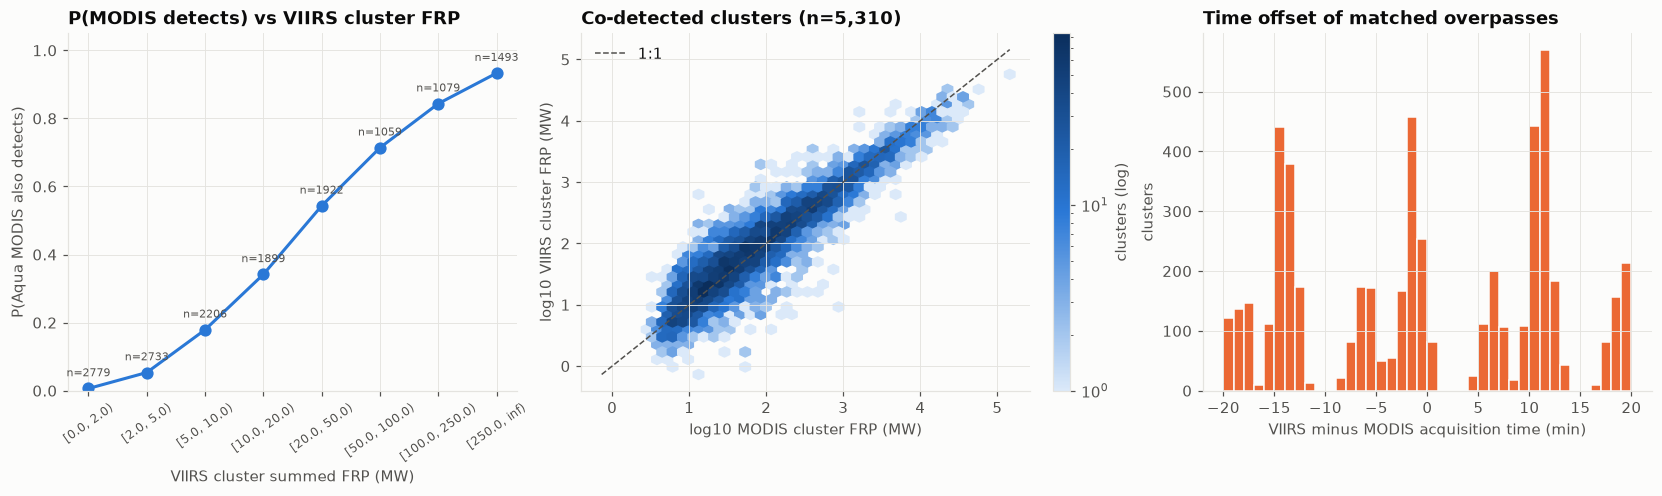

,frp_bin,n_viirs_clusters,n_with_modis,p_modis_detects
0,"[0.0, 2.0)",2779.0,18.0,0.006477
1,"[2.0, 5.0)",2733.0,146.0,0.053421
2,"[5.0, 10.0)",2206.0,395.0,0.179057
3,"[10.0, 20.0)",1899.0,649.0,0.341759
4,"[20.0, 50.0)",1922.0,1044.0,0.543184
5,"[50.0, 100.0)",1059.0,756.0,0.713881
6,"[100.0, 250.0)",1079.0,910.0,0.843373
7,"[250.0, 1000000000.0)",1493.0,1393.0,0.933021


In [12]:
res_path = S.reports_dir / "results" / f"harmonization_diagnostics_{REGION.name}_{TAG}.json"
diag = json.loads(res_path.read_text())
co = pd.DataFrame(diag["coincident"]).T[["n_clusters_eligible", "both", "modis_only", "viirs_only",
                                         "p_viirs_given_modis", "p_modis_given_viirs",
                                         "median_pixel_ratio_viirs_to_modis", "median_frp_ratio_viirs_to_modis",
                                         "frp_spearman_rho", "median_abs_dt_min"]]
display(co)

from firelens.io import read_parquet
cl = read_parquet(S.processed_dir / "clusters" / REGION.name / f"coincident_clusters_{START}_{END}_dt20.parquet")
e = cl[cl.eligible]
curve = pd.DataFrame(diag["coincident"]["max_dt_20min"]["modis_detection_curve"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
xs = np.arange(len(curve))
axes[0].plot(xs, curve.p_modis_detects, marker="o", ms=7, color=SENSOR_COLORS["MODIS"])
for xi, (p, n) in enumerate(zip(curve.p_modis_detects, curve.n_viirs_clusters)):
    axes[0].annotate(f"n={int(n)}", (xi, p if p == p else 0), xytext=(0, 8), textcoords="offset points",
                     ha="center", fontsize=7, color=plots.TEXT_2)
axes[0].set_xticks(xs, [b.replace("1000000000.0", "inf") for b in curve.frp_bin], rotation=35, fontsize=8)
axes[0].set_ylim(0, 1.05); axes[0].set_xlabel("VIIRS cluster summed FRP (MW)")
axes[0].set_ylabel("P(Aqua MODIS also detects)")
axes[0].set_title("P(MODIS detects) vs VIIRS cluster FRP")

b = e[(e.category == "both") & (e.frp_modis_mw > 0) & (e.frp_viirs_mw > 0)]
hb = axes[1].hexbin(np.log10(b.frp_modis_mw), np.log10(b.frp_viirs_mw), gridsize=35, bins="log",
                    cmap=plots.SEQ_BLUE, mincnt=1)
lim = [np.log10(b[["frp_modis_mw", "frp_viirs_mw"]].min().min()), np.log10(b[["frp_modis_mw", "frp_viirs_mw"]].max().max())]
axes[1].plot(lim, lim, ls="--", lw=1, color=plots.TEXT_2, label="1:1"); axes[1].legend(loc="upper left")
axes[1].set_xlabel("log10 MODIS cluster FRP (MW)"); axes[1].set_ylabel("log10 VIIRS cluster FRP (MW)")
axes[1].set_title(f"Co-detected clusters (n={len(b):,})")
fig.colorbar(hb, ax=axes[1], label="clusters (log)")

axes[2].hist(b.dt_viirs_minus_modis_min, bins=np.arange(-20, 21, 1), color=SENSOR_COLORS["VIIRS"], edgecolor=plots.SURFACE)
axes[2].set_xlabel("VIIRS minus MODIS acquisition time (min)"); axes[2].set_ylabel("clusters")
axes[2].set_title("Time offset of matched overpasses")
plots.save(fig, FIG, "09_coincident_sensitivity"); plt.show()
display(curve)

In [13]:
cm = pd.DataFrame({k.replace("cellmonth_", ""): v for k, v in diag.items() if k.startswith("cellmonth_")}).T
display(cm[["n_cell_months_active", "n_months", "share_both_detected", "share_viirs_only", "share_modis_only",
            "ratio_of_totals_viirs_to_modis", "ratio_of_totals_ci95", "spearman_rho",
            "median_cell_ratio_viirs_to_modis", "loglog_slope", "loglog_slope_ci95"]])

,n_cell_months_active,n_months,share_both_detected,share_viirs_only,share_modis_only,ratio_of_totals_viirs_to_modis,ratio_of_totals_ci95,spearman_rho,median_cell_ratio_viirs_to_modis,loglog_slope,loglog_slope_ci95
terra_aqua_n_detections,11053,48,0.432281,0.501764,0.065955,4.493447,"[4.23535, 4.724485]",0.40229,2.6,1.001318,"[0.937328, 1.035774]"
terra_aqua_n_conf_nominal_high,10806,48,0.428836,0.504905,0.066259,4.587363,"[4.295767, 4.836933]",0.389005,2.5,1.008045,"[0.937026, 1.045982]"
terra_aqua_frp_sum_mw,11053,48,0.432281,0.501764,0.065955,0.598922,"[0.553425, 0.701226]",0.522567,0.79475,0.852009,"[0.810386, 0.879954]"
aqua_only_n_detections,10619,48,0.331293,0.640927,0.02778,9.337258,"[8.66726, 10.234181]",0.417098,4.142857,1.116039,"[1.050174, 1.154485]"
aqua_only_n_conf_nominal_high,10394,48,0.328363,0.64239,0.029248,9.503425,"[8.793818, 10.367099]",0.403615,4.0,1.126512,"[1.059574, 1.164699]"
aqua_only_frp_sum_mw,10619,48,0.331199,0.641021,0.02778,1.136088,"[1.030243, 1.349431]",0.545351,1.414311,0.889029,"[0.848969, 0.916255]"


A log-log slope different from 1 means the VIIRS/MODIS ratio depends on fire activity level, so a
single multiplicative constant cannot convert one sensor's counts into the other's.

## 9. Global snapshot (2020-09-01) - verification of global retrieval

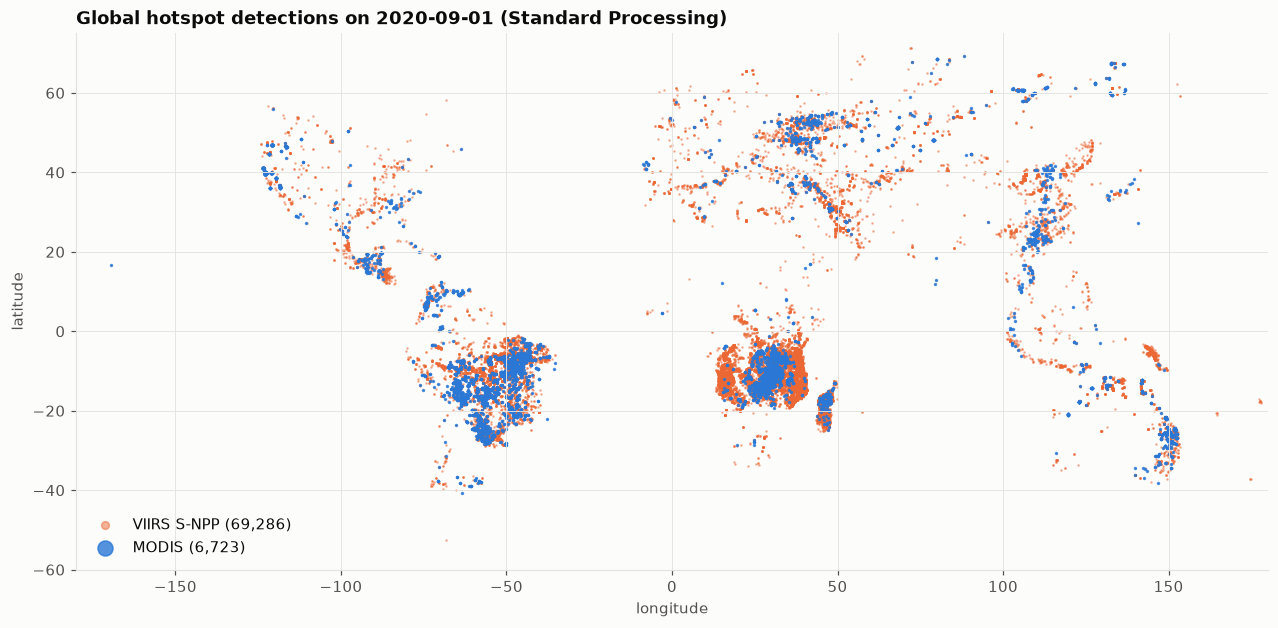

{'MODIS': 6723, 'VIIRS': 69286, 'ratio': 10.31, 'MODIS_usable': 6723, 'VIIRS_usable': 69286}


In [14]:
W = REGIONS["world"]
gm = load_detections(S, W, "MODIS_SP", date(2020, 9, 1), date(2020, 9, 1))
gv = load_detections(S, W, "VIIRS_SNPP_SP", date(2020, 9, 1), date(2020, 9, 1))
fig, ax = plt.subplots(figsize=(12, 5.6))
ax.scatter(gv.longitude, gv.latitude, s=0.4, color=SENSOR_COLORS["VIIRS"], alpha=0.5, label=f"VIIRS S-NPP ({len(gv):,})", rasterized=True)
ax.scatter(gm.longitude, gm.latitude, s=1.5, color=SENSOR_COLORS["MODIS"], alpha=0.8, label=f"MODIS ({len(gm):,})", rasterized=True)
ax.set_xlim(-180, 180); ax.set_ylim(-60, 75); ax.set_aspect(1.2)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Global hotspot detections on 2020-09-01 (Standard Processing)")
ax.legend(loc="lower left", markerscale=8)
plots.save(fig, FIG, "10_global_snapshot"); plt.show()
summary["global_2020_09_01"] = {"MODIS": len(gm), "VIIRS": len(gv), "ratio": round(len(gv) / len(gm), 2),
                                "MODIS_usable": int(gm.qc_usable.sum()), "VIIRS_usable": int(gv.qc_usable.sum())}
print(summary["global_2020_09_01"])

In [15]:
out = S.reports_dir / "results" / "eda_summary.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(summary, indent=2, default=str))
print("wrote", out)

wrote reports\results\eda_summary.json
